In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
df = pd.read_csv(r"C:\Users\Anindita\OneDrive\Desktop\credit-risk-prediction\data\raw\application_train.csv")

In [3]:
df.shape

(307511, 122)

In [4]:
df.head()

,SK_ID_CURR,TARGET,NAME_CONTRACT_TYPE,CODE_GENDER,FLAG_OWN_CAR,FLAG_OWN_REALTY,CNT_CHILDREN,AMT_INCOME_TOTAL,AMT_CREDIT,AMT_ANNUITY,...,FLAG_DOCUMENT_18,FLAG_DOCUMENT_19,FLAG_DOCUMENT_20,FLAG_DOCUMENT_21,AMT_REQ_CREDIT_BUREAU_HOUR,AMT_REQ_CREDIT_BUREAU_DAY,AMT_REQ_CREDIT_BUREAU_WEEK,AMT_REQ_CREDIT_BUREAU_MON,AMT_REQ_CREDIT_BUREAU_QRT,AMT_REQ_CREDIT_BUREAU_YEAR
0,100002,1,Cash loans,M,N,Y,0,202500.0,406597.5,24700.5,...,0,0,0,0,0.0,0.0,0.0,0.0,0.0,1.0
1,100003,0,Cash loans,F,N,N,0,270000.0,1293502.5,35698.5,...,0,0,0,0,0.0,0.0,0.0,0.0,0.0,0.0
2,100004,0,Revolving loans,M,Y,Y,0,67500.0,135000.0,6750.0,...,0,0,0,0,0.0,0.0,0.0,0.0,0.0,0.0
3,100006,0,Cash loans,F,N,Y,0,135000.0,312682.5,29686.5,...,0,0,0,0,NaN,NaN,NaN,NaN,NaN,NaN
4,100007,0,Cash loans,M,N,Y,0,121500.0,513000.0,21865.5,...,0,0,0,0,0.0,0.0,0.0,0.0,0.0,0.0


In [5]:
df.tail()

,SK_ID_CURR,TARGET,NAME_CONTRACT_TYPE,CODE_GENDER,FLAG_OWN_CAR,FLAG_OWN_REALTY,CNT_CHILDREN,AMT_INCOME_TOTAL,AMT_CREDIT,AMT_ANNUITY,...,FLAG_DOCUMENT_18,FLAG_DOCUMENT_19,FLAG_DOCUMENT_20,FLAG_DOCUMENT_21,AMT_REQ_CREDIT_BUREAU_HOUR,AMT_REQ_CREDIT_BUREAU_DAY,AMT_REQ_CREDIT_BUREAU_WEEK,AMT_REQ_CREDIT_BUREAU_MON,AMT_REQ_CREDIT_BUREAU_QRT,AMT_REQ_CREDIT_BUREAU_YEAR
307506,456251,0,Cash loans,M,N,N,0,157500.0,254700.0,27558.0,...,0,0,0,0,NaN,NaN,NaN,NaN,NaN,NaN
307507,456252,0,Cash loans,F,N,Y,0,72000.0,269550.0,12001.5,...,0,0,0,0,NaN,NaN,NaN,NaN,NaN,NaN
307508,456253,0,Cash loans,F,N,Y,0,153000.0,677664.0,29979.0,...,0,0,0,0,1.0,0.0,0.0,1.0,0.0,1.0
307509,456254,1,Cash loans,F,N,Y,0,171000.0,370107.0,20205.0,...,0,0,0,0,0.0,0.0,0.0,0.0,0.0,0.0
307510,456255,0,Cash loans,F,N,N,0,157500.0,675000.0,49117.5,...,0,0,0,0,0.0,0.0,0.0,2.0,0.0,1.0


In [6]:
df.columns

Index(['SK_ID_CURR', 'TARGET', 'NAME_CONTRACT_TYPE', 'CODE_GENDER',
       'FLAG_OWN_CAR', 'FLAG_OWN_REALTY', 'CNT_CHILDREN', 'AMT_INCOME_TOTAL',
       'AMT_CREDIT', 'AMT_ANNUITY',
       ...
       'FLAG_DOCUMENT_18', 'FLAG_DOCUMENT_19', 'FLAG_DOCUMENT_20',
       'FLAG_DOCUMENT_21', 'AMT_REQ_CREDIT_BUREAU_HOUR',
       'AMT_REQ_CREDIT_BUREAU_DAY', 'AMT_REQ_CREDIT_BUREAU_WEEK',
       'AMT_REQ_CREDIT_BUREAU_MON', 'AMT_REQ_CREDIT_BUREAU_QRT',
       'AMT_REQ_CREDIT_BUREAU_YEAR'],
      dtype='str', length=122)

In [7]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 307511 entries, 0 to 307510
Columns: 122 entries, SK_ID_CURR to AMT_REQ_CREDIT_BUREAU_YEAR
dtypes: float64(65), int64(41), str(16)
memory usage: 325.2 MB


In [8]:
df.describe()

,SK_ID_CURR,TARGET,CNT_CHILDREN,AMT_INCOME_TOTAL,AMT_CREDIT,AMT_ANNUITY,AMT_GOODS_PRICE,REGION_POPULATION_RELATIVE,DAYS_BIRTH,DAYS_EMPLOYED,...,FLAG_DOCUMENT_18,FLAG_DOCUMENT_19,FLAG_DOCUMENT_20,FLAG_DOCUMENT_21,AMT_REQ_CREDIT_BUREAU_HOUR,AMT_REQ_CREDIT_BUREAU_DAY,AMT_REQ_CREDIT_BUREAU_WEEK,AMT_REQ_CREDIT_BUREAU_MON,AMT_REQ_CREDIT_BUREAU_QRT,AMT_REQ_CREDIT_BUREAU_YEAR
count,307511.000000,307511.000000,307511.000000,3.075110e+05,3.075110e+05,307499.000000,3.072330e+05,307511.000000,307511.000000,307511.000000,...,307511.000000,307511.000000,307511.000000,307511.000000,265992.000000,265992.000000,265992.000000,265992.000000,265992.000000,265992.000000
mean,278180.518577,0.080729,0.417052,1.687979e+05,5.990260e+05,27108.573909,5.383962e+05,0.020868,-16036.995067,63815.045904,...,0.008130,0.000595,0.000507,0.000335,0.006402,0.007000,0.034362,0.267395,0.265474,1.899974
std,102790.175348,0.272419,0.722121,2.371231e+05,4.024908e+05,14493.737315,3.694465e+05,0.013831,4363.988632,141275.766519,...,0.089798,0.024387,0.022518,0.018299,0.083849,0.110757,0.204685,0.916002,0.794056,1.869295
min,100002.000000,0.000000,0.000000,2.565000e+04,4.500000e+04,1615.500000,4.050000e+04,0.000290,-25229.000000,-17912.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
25%,189145.500000,0.000000,0.000000,1.125000e+05,2.700000e+05,16524.000000,2.385000e+05,0.010006,-19682.000000,-2760.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
50%,278202.000000,0.000000,0.000000,1.471500e+05,5.135310e+05,24903.000000,4.500000e+05,0.018850,-15750.000000,-1213.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,1.000000
75%,367142.500000,0.000000,1.000000,2.025000e+05,8.086500e+05,34596.000000,6.795000e+05,0.028663,-12413.000000,-289.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,3.000000
max,456255.000000,1.000000,19.000000,1.170000e+08,4.050000e+06,258025.500000,4.050000e+06,0.072508,-7489.000000,365243.000000,...,1.000000,1.000000,1.000000,1.000000,4.000000,9.000000,8.000000,27.000000,261.000000,25.000000


In [9]:
df.columns.tolist()

['SK_ID_CURR',
 'TARGET',
 'NAME_CONTRACT_TYPE',
 'CODE_GENDER',
 'FLAG_OWN_CAR',
 'FLAG_OWN_REALTY',
 'CNT_CHILDREN',
 'AMT_INCOME_TOTAL',
 'AMT_CREDIT',
 'AMT_ANNUITY',
 'AMT_GOODS_PRICE',
 'NAME_TYPE_SUITE',
 'NAME_INCOME_TYPE',
 'NAME_EDUCATION_TYPE',
 'NAME_FAMILY_STATUS',
 'NAME_HOUSING_TYPE',
 'REGION_POPULATION_RELATIVE',
 'DAYS_BIRTH',
 'DAYS_EMPLOYED',
 'DAYS_REGISTRATION',
 'DAYS_ID_PUBLISH',
 'OWN_CAR_AGE',
 'FLAG_MOBIL',
 'FLAG_EMP_PHONE',
 'FLAG_WORK_PHONE',
 'FLAG_CONT_MOBILE',
 'FLAG_PHONE',
 'FLAG_EMAIL',
 'OCCUPATION_TYPE',
 'CNT_FAM_MEMBERS',
 'REGION_RATING_CLIENT',
 'REGION_RATING_CLIENT_W_CITY',
 'WEEKDAY_APPR_PROCESS_START',
 'HOUR_APPR_PROCESS_START',
 'REG_REGION_NOT_LIVE_REGION',
 'REG_REGION_NOT_WORK_REGION',
 'LIVE_REGION_NOT_WORK_REGION',
 'REG_CITY_NOT_LIVE_CITY',
 'REG_CITY_NOT_WORK_CITY',
 'LIVE_CITY_NOT_WORK_CITY',
 'ORGANIZATION_TYPE',
 'EXT_SOURCE_1',
 'EXT_SOURCE_2',
 'EXT_SOURCE_3',
 'APARTMENTS_AVG',
 'BASEMENTAREA_AVG',
 'YEARS_BEGINEXPLUATATION_A

In [10]:
df["TARGET"].value_counts() # it is binary classigication problem

TARGET
0    282686
1     24825
Name: count, dtype: int64

In [11]:
#TARGET = 0 (repaid the loan)
#TARGET = 1 (had payment difficulties/defaulted)

df["TARGET"].value_counts(normalize=True) * 100 # class imbalance

TARGET
0    91.927118
1     8.072882
Name: proportion, dtype: float64

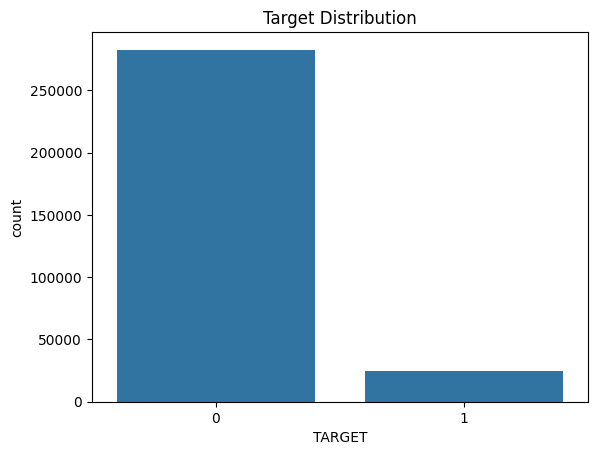

In [12]:
sns.countplot(x="TARGET", data=df)  # count occurrences of each TARGET value
plt.title("Target Distribution")    # add a title above the chart
plt.show()                          # render the plot

In [13]:
missing = df.isnull().sum()  #Counts how many missing values exist in each column of your dataframe.
missing = missing[missing > 0].sort_values(ascending=False)
# keeps only columns that actually have missing values and reorders them so the worst offenders come first
missing.head(20)

COMMONAREA_MEDI             214865
COMMONAREA_MODE             214865
COMMONAREA_AVG              214865
NONLIVINGAPARTMENTS_MODE    213514
NONLIVINGAPARTMENTS_MEDI    213514
NONLIVINGAPARTMENTS_AVG     213514
FONDKAPREMONT_MODE          210295
LIVINGAPARTMENTS_AVG        210199
LIVINGAPARTMENTS_MEDI       210199
LIVINGAPARTMENTS_MODE       210199
FLOORSMIN_MEDI              208642
FLOORSMIN_MODE              208642
FLOORSMIN_AVG               208642
YEARS_BUILD_MODE            204488
YEARS_BUILD_MEDI            204488
YEARS_BUILD_AVG             204488
OWN_CAR_AGE                 202929
LANDAREA_AVG                182590
LANDAREA_MEDI               182590
LANDAREA_MODE               182590
dtype: int64

In [14]:
missing_percentage = (
    df.isnull().mean() * 100
).sort_values(ascending=False)

missing_percentage.head(20)

COMMONAREA_AVG              69.872297
COMMONAREA_MODE             69.872297
COMMONAREA_MEDI             69.872297
NONLIVINGAPARTMENTS_MEDI    69.432963
NONLIVINGAPARTMENTS_MODE    69.432963
NONLIVINGAPARTMENTS_AVG     69.432963
FONDKAPREMONT_MODE          68.386172
LIVINGAPARTMENTS_AVG        68.354953
LIVINGAPARTMENTS_MEDI       68.354953
LIVINGAPARTMENTS_MODE       68.354953
FLOORSMIN_MODE              67.848630
FLOORSMIN_AVG               67.848630
FLOORSMIN_MEDI              67.848630
YEARS_BUILD_AVG             66.497784
YEARS_BUILD_MODE            66.497784
YEARS_BUILD_MEDI            66.497784
OWN_CAR_AGE                 65.990810
LANDAREA_MEDI               59.376738
LANDAREA_AVG                59.376738
LANDAREA_MODE               59.376738
dtype: float64

In [15]:
# Get all numeric columns (whole numbers and decimals) from the dataframe
numeric_columns = df.select_dtypes(
    include = ['int64', 'float64']   # only keep columns with these two data types
).columns                            # grab just the column names, not the data 

# Get all categorical/text columns from the dataframe
categorical_columns = df.select_dtypes(
    include = ['object']            # 'object' dtype = text/string columns in pandas
).columns                           # grab just the column names, not the data 

print("Numericl columns:", len(numeric_columns))  
print("Categorical columns:", len(categorical_columns))

Numericl columns: 106
Categorical columns: 16


C:\Users\Anindita\AppData\Local\Temp\ipykernel_38252\1377321436.py:7: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  categorical_columns = df.select_dtypes(


In [16]:
print(categorical_columns.tolist())

['NAME_CONTRACT_TYPE', 'CODE_GENDER', 'FLAG_OWN_CAR', 'FLAG_OWN_REALTY', 'NAME_TYPE_SUITE', 'NAME_INCOME_TYPE', 'NAME_EDUCATION_TYPE', 'NAME_FAMILY_STATUS', 'NAME_HOUSING_TYPE', 'OCCUPATION_TYPE', 'WEEKDAY_APPR_PROCESS_START', 'ORGANIZATION_TYPE', 'FONDKAPREMONT_MODE', 'HOUSETYPE_MODE', 'WALLSMATERIAL_MODE', 'EMERGENCYSTATE_MODE']


In [17]:
df.duplicated().sum()

np.int64(0)

In [18]:
df.columns

Index(['SK_ID_CURR', 'TARGET', 'NAME_CONTRACT_TYPE', 'CODE_GENDER',
       'FLAG_OWN_CAR', 'FLAG_OWN_REALTY', 'CNT_CHILDREN', 'AMT_INCOME_TOTAL',
       'AMT_CREDIT', 'AMT_ANNUITY',
       ...
       'FLAG_DOCUMENT_18', 'FLAG_DOCUMENT_19', 'FLAG_DOCUMENT_20',
       'FLAG_DOCUMENT_21', 'AMT_REQ_CREDIT_BUREAU_HOUR',
       'AMT_REQ_CREDIT_BUREAU_DAY', 'AMT_REQ_CREDIT_BUREAU_WEEK',
       'AMT_REQ_CREDIT_BUREAU_MON', 'AMT_REQ_CREDIT_BUREAU_QRT',
       'AMT_REQ_CREDIT_BUREAU_YEAR'],
      dtype='str', length=122)

In [19]:
df[[
    "AMT_INCOME_TOTAL",
    "AMT_CREDIT",
    "AMT_ANNUITY",
    "AMT_GOODS_PRICE",
    "DAYS_BIRTH",
    "DAYS_EMPLOYED",
    "TARGET"
]].describe()

,AMT_INCOME_TOTAL,AMT_CREDIT,AMT_ANNUITY,AMT_GOODS_PRICE,DAYS_BIRTH,DAYS_EMPLOYED,TARGET
count,3.075110e+05,3.075110e+05,307499.000000,3.072330e+05,307511.000000,307511.000000,307511.000000
mean,1.687979e+05,5.990260e+05,27108.573909,5.383962e+05,-16036.995067,63815.045904,0.080729
std,2.371231e+05,4.024908e+05,14493.737315,3.694465e+05,4363.988632,141275.766519,0.272419
min,2.565000e+04,4.500000e+04,1615.500000,4.050000e+04,-25229.000000,-17912.000000,0.000000
25%,1.125000e+05,2.700000e+05,16524.000000,2.385000e+05,-19682.000000,-2760.000000,0.000000
50%,1.471500e+05,5.135310e+05,24903.000000,4.500000e+05,-15750.000000,-1213.000000,0.000000
75%,2.025000e+05,8.086500e+05,34596.000000,6.795000e+05,-12413.000000,-289.000000,0.000000
max,1.170000e+08,4.050000e+06,258025.500000,4.050000e+06,-7489.000000,365243.000000,1.000000


In [20]:
# DAYS_BIRTH is stored as a negative number (days before the application date),
# so negate it to make it positive, then divide by 365 to convert days into years
df["AGE_YEARS"] = -df["DAYS_BIRTH"] / 365

C:\Users\Anindita\AppData\Local\Temp\ipykernel_38252\2039823527.py:3: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  df["AGE_YEARS"] = -df["DAYS_BIRTH"] / 365


In [21]:
df["AGE_YEARS"].describe()

count    307511.000000
mean         43.936973
std          11.956133
min          20.517808
25%          34.008219
50%          43.150685
75%          53.923288
max          69.120548
Name: AGE_YEARS, dtype: float64

In [22]:
# Create a new feature: how large the loan is relative to the person's income.
# Dividing credit amount by income gives a ratio (e.g. 3.0 means the loan
# is 3x the person's total income) — a common signal of repayment risk.
df['CREDIT_INCOME_RATIO'] = (
    df['AMT_CREDIT'] / df['AMT_INCOME_TOTAL']
)                                                  

C:\Users\Anindita\AppData\Local\Temp\ipykernel_38252\3143245129.py:4: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  df['CREDIT_INCOME_RATIO'] = (


In [23]:
# Create a new feature: what fraction of the person's income goes toward
# the loan's annual payment (annuity). A higher ratio means a bigger chunk
# of income is committed to repayment — another common risk signal.
   
df["ANNUITY_INCOME_RATIO"] = (
    df["AMT_ANNUITY"] / df["AMT_INCOME_TOTAL"]
)

C:\Users\Anindita\AppData\Local\Temp\ipykernel_38252\1102742928.py:5: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  df["ANNUITY_INCOME_RATIO"] = (


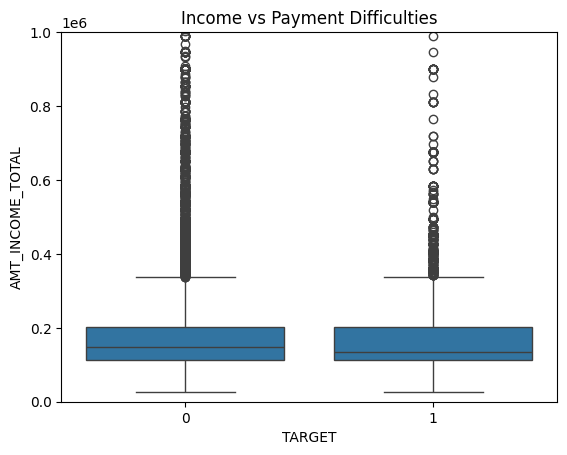

In [24]:
sns.boxplot(
    x = 'TARGET',              # categorical variable on the x-axis (the groups)
    y = 'AMT_INCOME_TOTAL',    # numeric variable on the y-axis (what gets plotted)
    data = df                  # the dataframe these columns come from
)

plt.ylim(0, 1000000)   # forces y-axis to go from 0 to 1,000,000
plt.title("Income vs Payment Difficulties")  # shows the title 
plt.show()

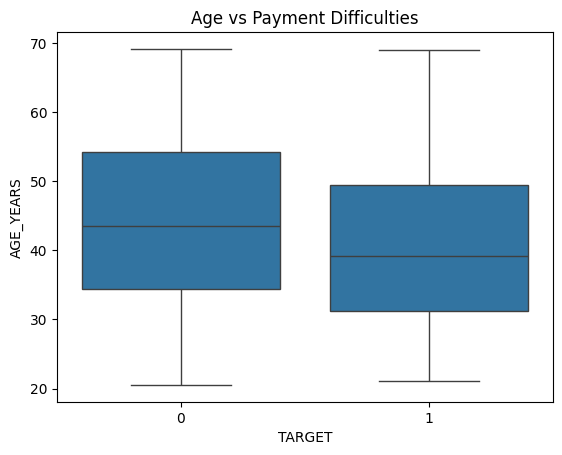

In [25]:
sns.boxplot(
    x = 'TARGET',
    y = 'AGE_YEARS',
    data = df
)

plt.title('Age vs Payment Difficulties')
plt.show()

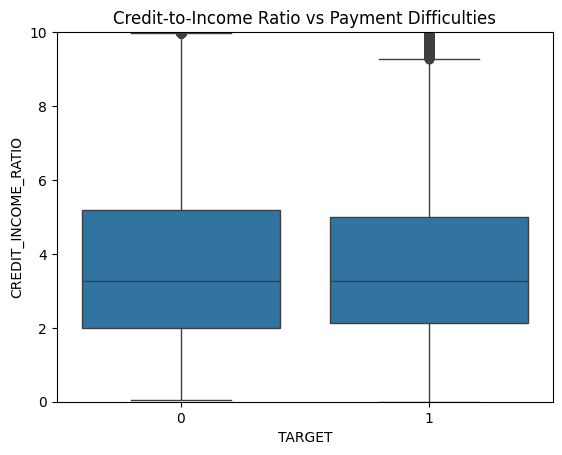

In [26]:
sns.boxplot(
    x = 'TARGET',
    y = 'CREDIT_INCOME_RATIO',
    data = df
)

plt.ylim(0, 10)
plt.title('Credit-to-Income Ratio vs Payment Difficulties')
plt.show()

In [27]:
eda_df = df.copy()

In [28]:
eda_df.shape

(307511, 125)

# Target Distribution

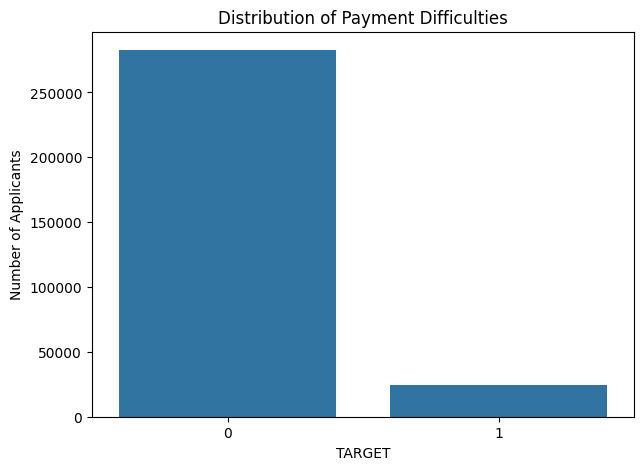

In [29]:
#counts how many applicants have 
#TARGET = 0 (repaid the loan) 
#TARGET = 1 (had payment difficulties/defaulted)

target_counts = eda_df['TARGET'].value_counts()

plt.figure(figsize = (7, 5))
sns.barplot(
    x = target_counts.index,
    y = target_counts.values
)

plt.title('Distribution of Payment Difficulties')
plt.xlabel('TARGET')
plt.ylabel('Number of Applicants')
plt.show()

In [30]:
target_percentage = (
    eda_df['TARGET']
    .value_counts(normalize = True)
    .mul(100)
)

print(target_percentage)

TARGET
0    91.927118
1     8.072882
Name: proportion, dtype: float64


# Age Analysis

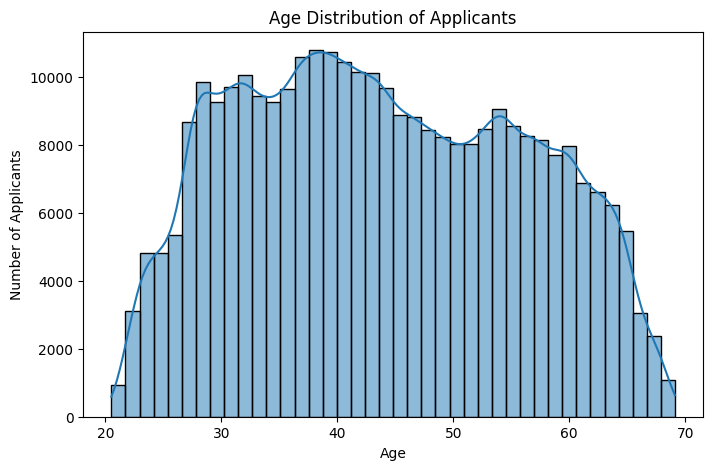

In [33]:
# Set the figure size to 8x5 inches so the chart is a good readable size
plt.figure(figsize = (8, 5))

# Plot a histogram of applicant ages
sns.histplot(
    data = eda_df,       # use the EDA copy of the dataframe
    x = 'AGE_YEARS',     # column to plot on the x-axis (the age feature we engineered earlier)
    bins = 40,           # split the age range into 40 bars — more bins = finer detail
    kde = True           # overlay a smooth curve (Kernel Density Estimate) showing the overall shape of the distribution
)

plt.title("Age Distribution of Applicants")
plt.xlabel("Age")
plt.ylabel("Number of Applicants")
plt.show()

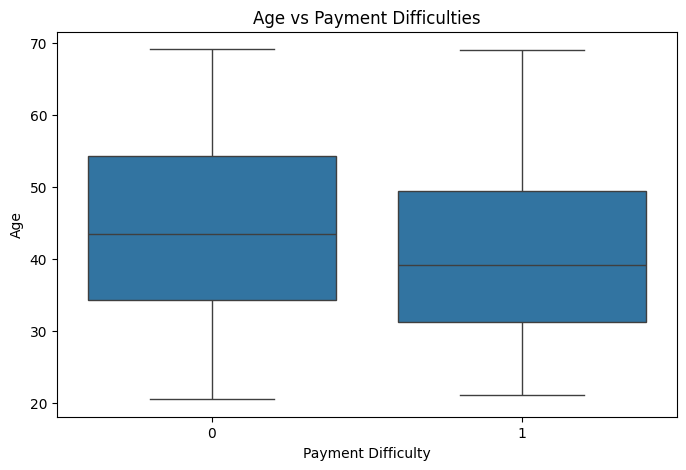

In [34]:
plt.figure(figsize = (8, 5))

sns.boxplot(
    data = eda_df,
    x = "TARGET",
    y = "AGE_YEARS"
)

plt.title("Age vs Payment Difficulties")
plt.xlabel("Payment Difficulty")
plt.ylabel("Age")
plt.show()

In [35]:
eda_df.groupby("TARGET")["AGE_YEARS"].mean()

TARGET
0    44.214182
1    40.780351
Name: AGE_YEARS, dtype: float64

# Income Analysis

In [36]:
eda_df["AMT_INCOME_TOTAL"].describe()

count    3.075110e+05
mean     1.687979e+05
std      2.371231e+05
min      2.565000e+04
25%      1.125000e+05
50%      1.471500e+05
75%      2.025000e+05
max      1.170000e+08
Name: AMT_INCOME_TOTAL, dtype: float64

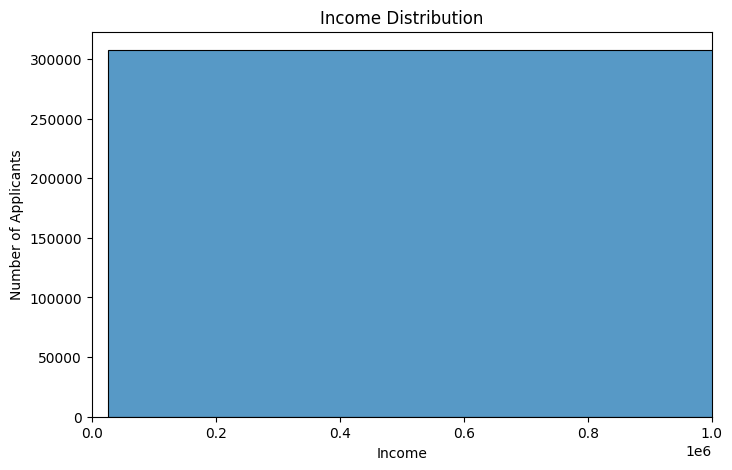

In [40]:
# Set the figure size to 8x5 inches so the chart
plt.figure(figsize = (8, 5))

sns.histplot(
    data = eda_df,
    x = 'AMT_INCOME_TOTAL',
    bins = 50               # split the income range into 50 bars for finer detail
)

plt.xlim(0, 1000000)

plt.title("Income Distribution")
plt.xlabel("Income")
plt.ylabel("Number of Applicants")
plt.show()

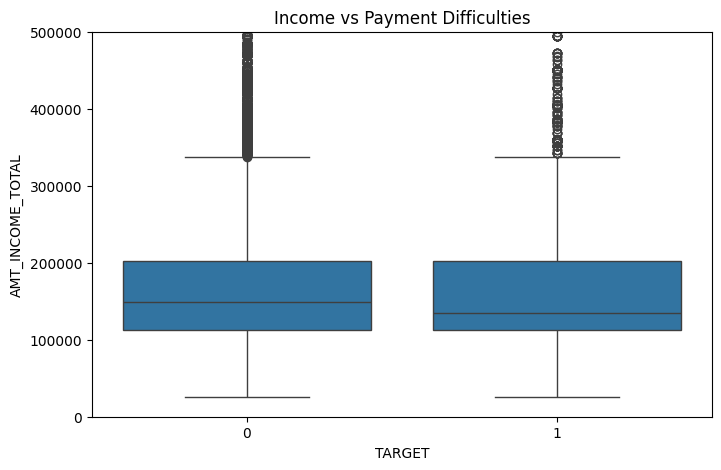

In [41]:
plt.figure(figsize=(8, 5))

sns.boxplot(
    x = "TARGET",
    y = "AMT_INCOME_TOTAL",
    data = eda_df
)

plt.ylim(0, 500000)

plt.title("Income vs Payment Difficulties")
plt.show()

In [42]:
# Group applicants by TARGET (0 = repaid, 1 = defaulted),
# then calculate the average income within each group,
# to compare typical income between the two groups
eda_df.groupby("TARGET")["AMT_INCOME_TOTAL"].mean()

TARGET
0    169077.722266
1    165611.760906
Name: AMT_INCOME_TOTAL, dtype: float64

# Loan Amount Analysis

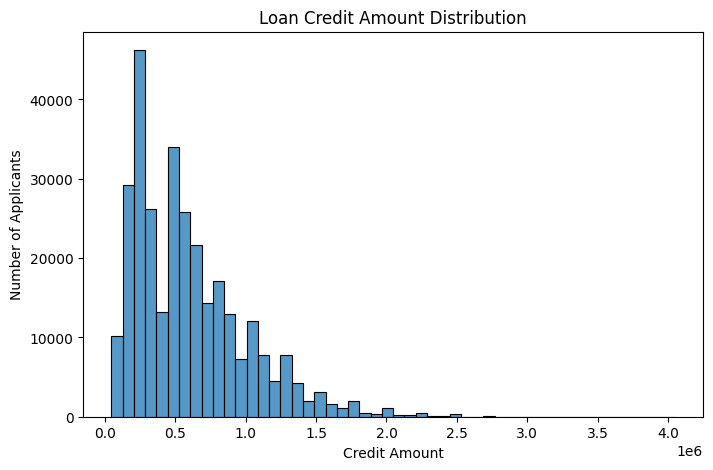

In [43]:
plt.figure(figsize = (8, 5))

sns.histplot(
    x = "AMT_CREDIT",
    data = eda_df,
    bins = 50
)

plt.title("Loan Credit Amount Distribution")
plt.xlabel("Credit Amount")
plt.ylabel("Number of Applicants")

plt.show()

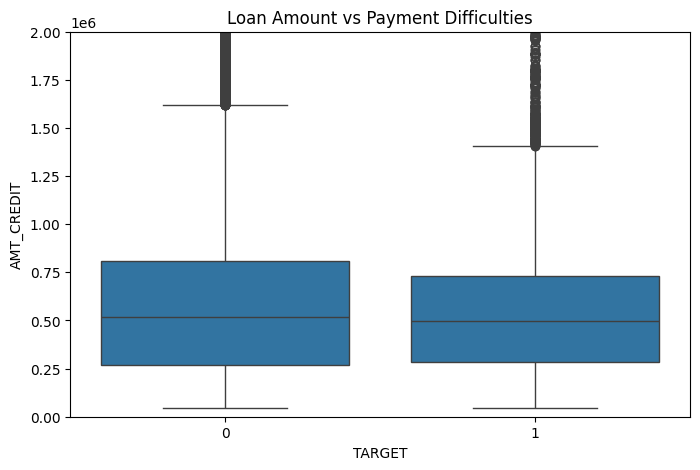

In [44]:
plt.figure(figsize = (8, 5))

sns.boxplot(
    x = "TARGET",
    y = "AMT_CREDIT",
    data = eda_df
)

plt.ylim(0, 2000000)
plt.title("Loan Amount vs Payment Difficulties")
plt.show()

In [45]:
eda_df.groupby("TARGET")["AMT_CREDIT"].mean()

TARGET
0    602648.282002
1    557778.527674
Name: AMT_CREDIT, dtype: float64

# Credit-to-Income Ratio

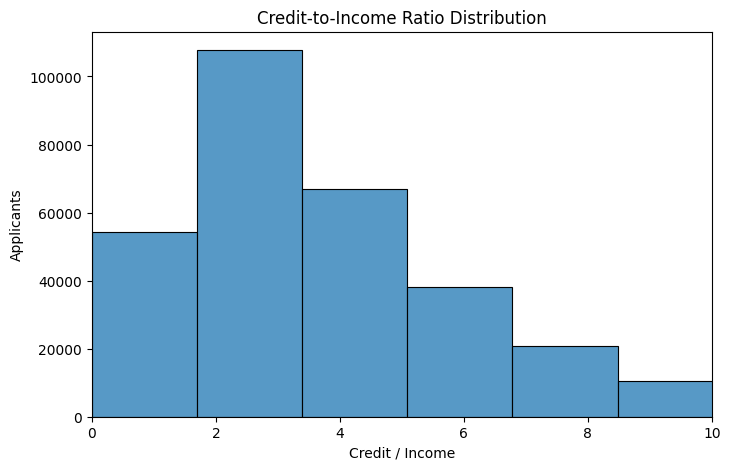

In [49]:
plt.figure(figsize=(8, 5))

sns.histplot(
    data=eda_df,
    x="CREDIT_INCOME_RATIO",
    bins=50
)

plt.xlim(0, 10)

plt.title("Credit-to-Income Ratio Distribution")
plt.xlabel("Credit / Income")
plt.ylabel("Applicants")

plt.show()

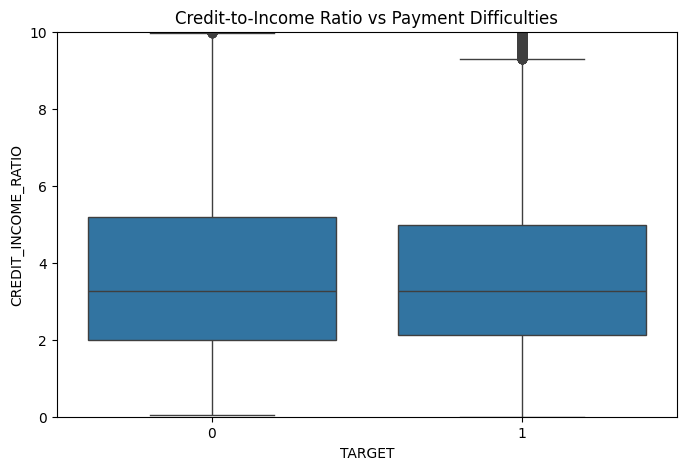

In [50]:
plt.figure(figsize = (8,5))

sns.boxplot(
    x = "TARGET",
    y = "CREDIT_INCOME_RATIO",
    data = eda_df
)

plt.ylim(0, 10)
plt.title("Credit-to-Income Ratio vs Payment Difficulties")
plt.show()

In [51]:
eda_df.groupby("TARGET")["CREDIT_INCOME_RATIO"].mean()

TARGET
0    3.963729
1    3.887438
Name: CREDIT_INCOME_RATIO, dtype: float64

# Employment Analysis

In [52]:
eda_df["EMPLOYMENT_YEARS"] = (-eda_df["DAYS_EMPLOYED"] / 365)

In [53]:
eda_df["EMPLOYMENT_YEARS"].describe()

count    307511.000000
mean       -174.835742
std         387.056895
min       -1000.665753
25%           0.791781
50%           3.323288
75%           7.561644
max          49.073973
Name: EMPLOYMENT_YEARS, dtype: float64

In [54]:
eda_df["DAYS_EMPLOYED"].value_counts().head()

DAYS_EMPLOYED
 365243    55374
-200         156
-224         152
-199         151
-230         151
Name: count, dtype: int64

# Education Analysis

In [55]:
eda_df["NAME_EDUCATION_TYPE"].value_counts()

NAME_EDUCATION_TYPE
Secondary / secondary special    218391
Higher education                  74863
Incomplete higher                 10277
Lower secondary                    3816
Academic degree                     164
Name: count, dtype: int64

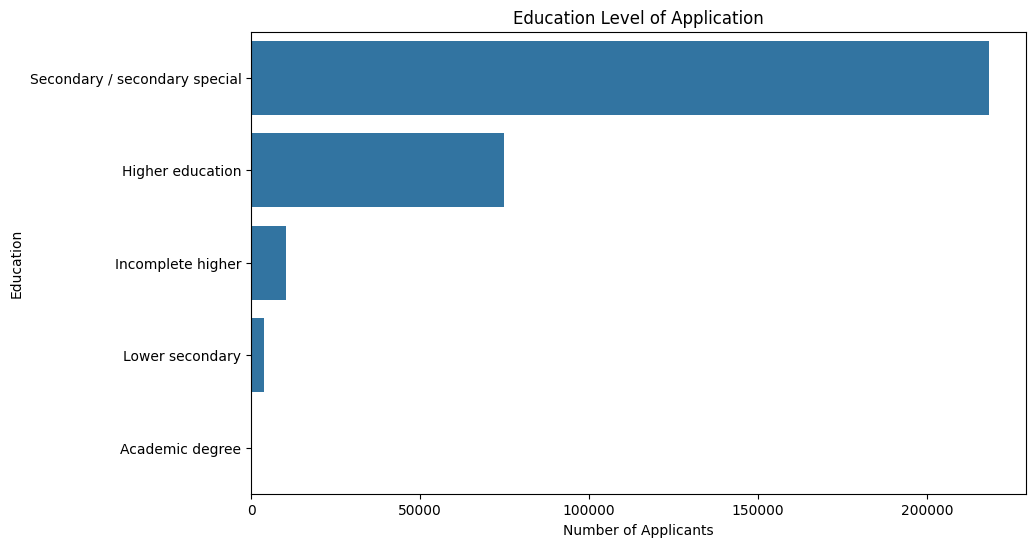

In [56]:
plt.figure(figsize = (10, 6))

sns.countplot(
    data  = eda_df,
    y = "NAME_EDUCATION_TYPE",
    order = eda_df["NAME_EDUCATION_TYPE"].value_counts().index
)

plt.title("Education Level of Application")
plt.xlabel("Number of Applicants")
plt.ylabel("Education")

plt.show()

In [57]:
education_default = (
    eda_df.groupby("NAME_EDUCATION_TYPE")["TARGET"]
    .mean()
    .sort_values(ascending = False)
)

print(education_default)

NAME_EDUCATION_TYPE
Lower secondary                  0.109277
Secondary / secondary special    0.089399
Incomplete higher                0.084850
Higher education                 0.053551
Academic degree                  0.018293
Name: TARGET, dtype: float64


In [60]:
education_default * 100

NAME_EDUCATION_TYPE
Lower secondary                  10.927673
Secondary / secondary special     8.939929
Incomplete higher                 8.484966
Higher education                  5.355115
Academic degree                   1.829268
Name: TARGET, dtype: float64

# Income Type Analysis

In [61]:
eda_df['NAME_INCOME_TYPE'].value_counts()

NAME_INCOME_TYPE
Working                 158774
Commercial associate     71617
Pensioner                55362
State servant            21703
Unemployed                  22
Student                     18
Businessman                 10
Maternity leave              5
Name: count, dtype: int64

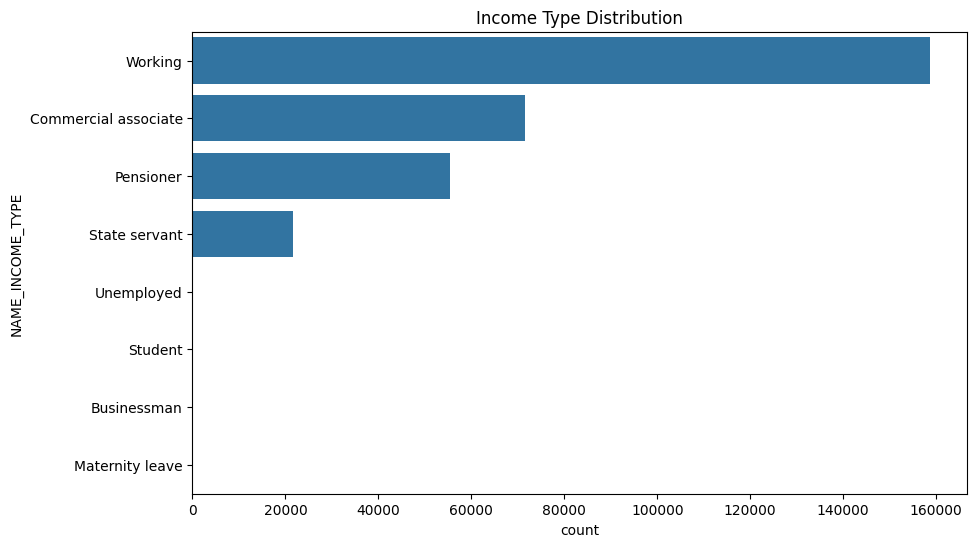

In [65]:
plt.figure(figsize =(10, 6))

sns.countplot(
    data = eda_df,
    y = 'NAME_INCOME_TYPE',
    order = eda_df["NAME_INCOME_TYPE"].value_counts().index
)

plt.title("Income Type Distribution")

plt.show()

In [66]:
income_type_default = (
    eda_df.groupby("NAME_INCOME_TYPE")["TARGET"]
    .mean()
    .sort_values(ascending=False)
)

print(income_type_default * 100)

NAME_INCOME_TYPE
Maternity leave         40.000000
Unemployed              36.363636
Working                  9.588472
Commercial associate     7.484257
State servant            5.754965
Pensioner                5.386366
Businessman              0.000000
Student                  0.000000
Name: TARGET, dtype: float64


# External Credit Scores

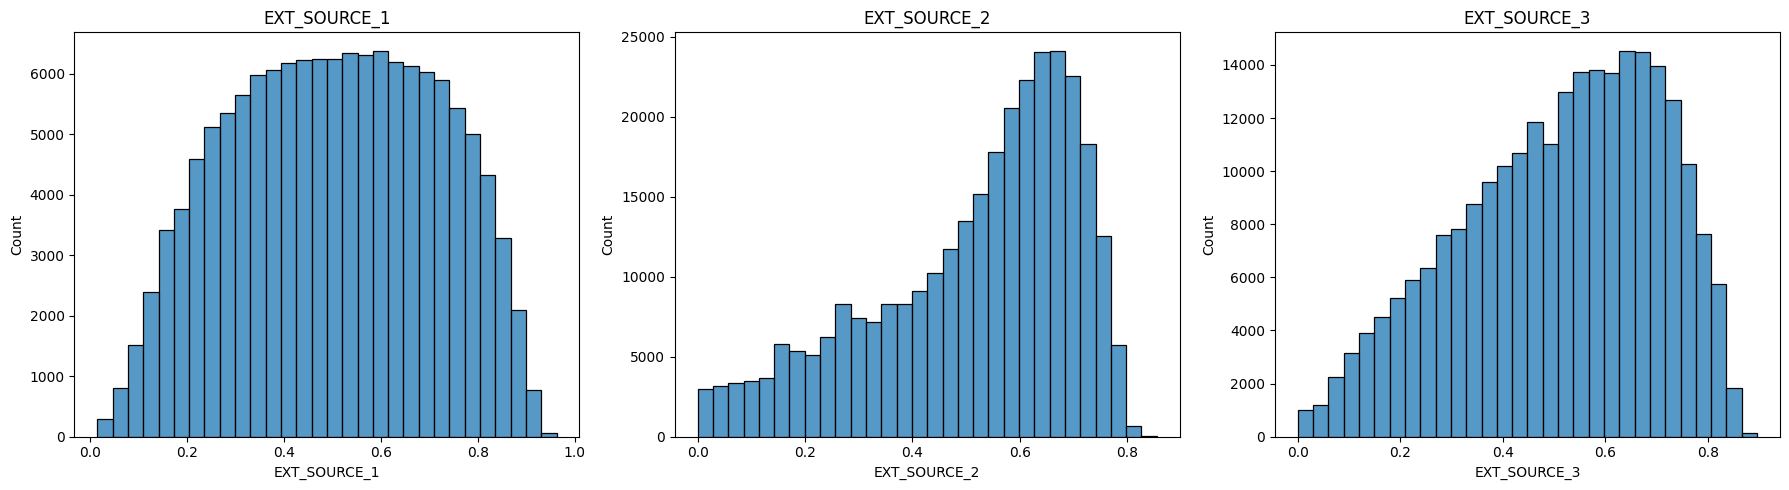

In [67]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

sns.histplot(
    eda_df["EXT_SOURCE_1"],
    bins=30,
    ax=axes[0]
)

axes[0].set_title("EXT_SOURCE_1")

sns.histplot(
    eda_df["EXT_SOURCE_2"],
    bins=30,
    ax=axes[1]
)

axes[1].set_title("EXT_SOURCE_2")

sns.histplot(
    eda_df["EXT_SOURCE_3"],
    bins=30,
    ax=axes[2]
)

axes[2].set_title("EXT_SOURCE_3")

plt.tight_layout()
plt.show()

In [68]:
for column in [
    "EXT_SOURCE_1",
    "EXT_SOURCE_2",
    "EXT_SOURCE_3"
]:
    print(
        column,
        eda_df.groupby("TARGET")[column].mean()
    )

EXT_SOURCE_1 TARGET
0    0.511461
1    0.386968
Name: EXT_SOURCE_1, dtype: float64
EXT_SOURCE_2 TARGET
0    0.523479
1    0.410935
Name: EXT_SOURCE_2, dtype: float64
EXT_SOURCE_3 TARGET
0    0.520969
1    0.390717
Name: EXT_SOURCE_3, dtype: float64


# Correlation Analysis

In [69]:
numeric_df = eda_df.select_dtypes(
    include=["int64", "float64"]
)

In [70]:
target_corr = (
    numeric_df.corr()["TARGET"]
    .sort_values()
)

print(target_corr.head(15))

EXT_SOURCE_3                 -0.178919
EXT_SOURCE_2                 -0.160472
EXT_SOURCE_1                 -0.155317
AGE_YEARS                    -0.078239
DAYS_EMPLOYED                -0.044932
FLOORSMAX_AVG                -0.044003
FLOORSMAX_MEDI               -0.043768
FLOORSMAX_MODE               -0.043226
AMT_GOODS_PRICE              -0.039645
REGION_POPULATION_RELATIVE   -0.037227
ELEVATORS_AVG                -0.034199
ELEVATORS_MEDI               -0.033863
FLOORSMIN_AVG                -0.033614
FLOORSMIN_MEDI               -0.033394
LIVINGAREA_AVG               -0.032997
Name: TARGET, dtype: float64


In [71]:
print(target_corr.tail(15))

DEF_30_CNT_SOCIAL_CIRCLE       0.032248
LIVE_CITY_NOT_WORK_CITY        0.032518
OWN_CAR_AGE                    0.037612
DAYS_REGISTRATION              0.041975
FLAG_DOCUMENT_3                0.044346
REG_CITY_NOT_LIVE_CITY         0.044395
EMPLOYMENT_YEARS               0.044932
FLAG_EMP_PHONE                 0.045982
REG_CITY_NOT_WORK_CITY         0.050994
DAYS_ID_PUBLISH                0.051457
DAYS_LAST_PHONE_CHANGE         0.055218
REGION_RATING_CLIENT           0.058899
REGION_RATING_CLIENT_W_CITY    0.060893
DAYS_BIRTH                     0.078239
TARGET                         1.000000
Name: TARGET, dtype: float64


In [72]:
target_corr.head(10)

EXT_SOURCE_3                 -0.178919
EXT_SOURCE_2                 -0.160472
EXT_SOURCE_1                 -0.155317
AGE_YEARS                    -0.078239
DAYS_EMPLOYED                -0.044932
FLOORSMAX_AVG                -0.044003
FLOORSMAX_MEDI               -0.043768
FLOORSMAX_MODE               -0.043226
AMT_GOODS_PRICE              -0.039645
REGION_POPULATION_RELATIVE   -0.037227
Name: TARGET, dtype: float64

In [73]:
target_corr.tail(10)

REG_CITY_NOT_LIVE_CITY         0.044395
EMPLOYMENT_YEARS               0.044932
FLAG_EMP_PHONE                 0.045982
REG_CITY_NOT_WORK_CITY         0.050994
DAYS_ID_PUBLISH                0.051457
DAYS_LAST_PHONE_CHANGE         0.055218
REGION_RATING_CLIENT           0.058899
REGION_RATING_CLIENT_W_CITY    0.060893
DAYS_BIRTH                     0.078239
TARGET                         1.000000
Name: TARGET, dtype: float64

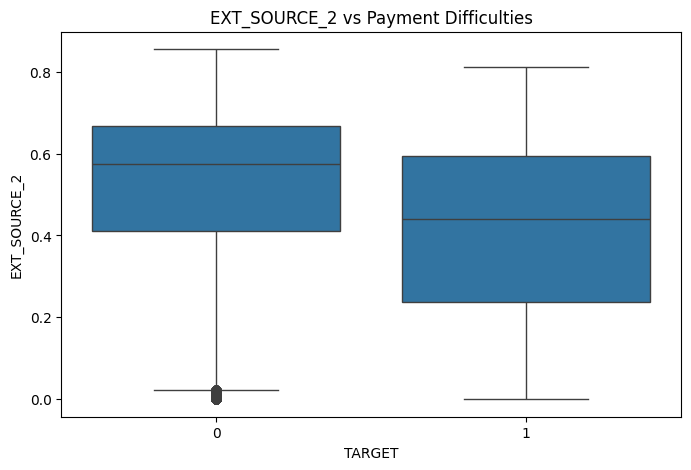

In [74]:
plt.figure(figsize=(8, 5))

sns.boxplot(
    data = eda_df,
    x = 'TARGET',
    y = 'EXT_SOURCE_2'
)

plt.title("EXT_SOURCE_2 vs Payment Difficulties")
plt.show()

# Missing Value Analysis

In [75]:
missing_table = pd.DataFrame({
    "Missing_Count": eda_df.isnull().sum(),
    "Missing_Percentage": eda_df.isnull().mean() * 100
})

missing_table = (
    missing_table[
        missing_table["Missing_Count"] > 0
    ]
    .sort_values(
        "Missing_Percentage",
        ascending=False
    )
)

missing_table.head(20)

,Missing_Count,Missing_Percentage
COMMONAREA_MODE,214865,69.872297
COMMONAREA_MEDI,214865,69.872297
COMMONAREA_AVG,214865,69.872297
NONLIVINGAPARTMENTS_AVG,213514,69.432963
NONLIVINGAPARTMENTS_MEDI,213514,69.432963
NONLIVINGAPARTMENTS_MODE,213514,69.432963
FONDKAPREMONT_MODE,210295,68.386172
LIVINGAPARTMENTS_MODE,210199,68.354953
LIVINGAPARTMENTS_MEDI,210199,68.354953
LIVINGAPARTMENTS_AVG,210199,68.354953


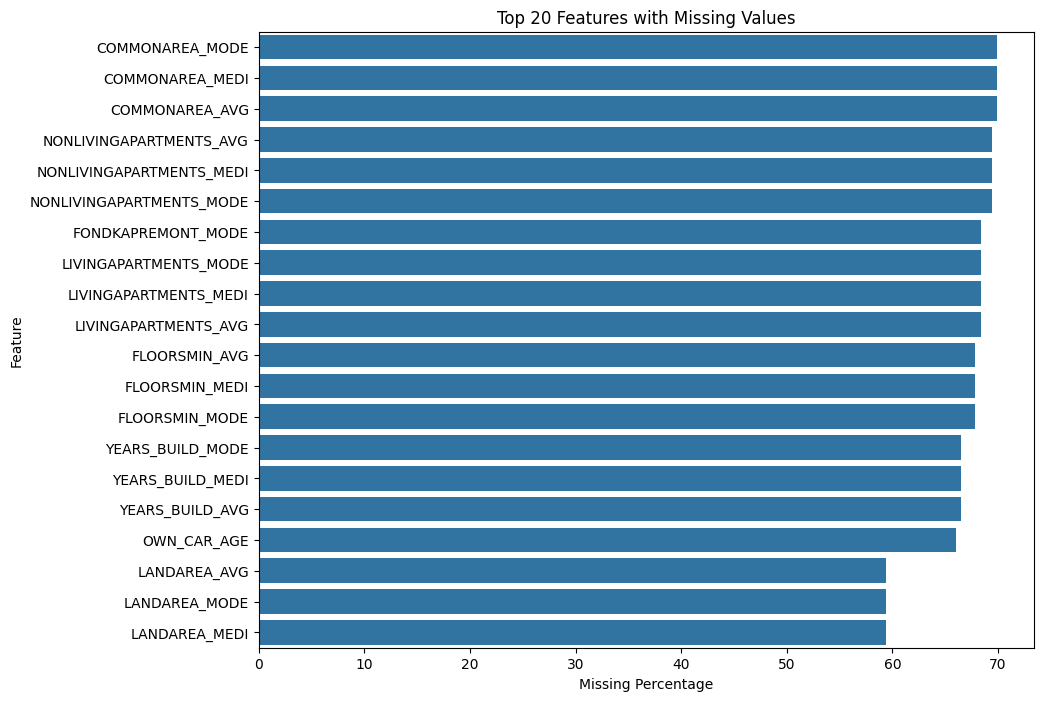

In [76]:
plt.figure(figsize=(10, 8))

sns.barplot(
    x=missing_table["Missing_Percentage"].head(20),
    y=missing_table.head(20).index
)

plt.title("Top 20 Features with Missing Values")
plt.xlabel("Missing Percentage")
plt.ylabel("Feature")

plt.show()

# Outlier Analysis

In [77]:
important_features = [
    "AMT_INCOME_TOTAL",
    "AMT_CREDIT",
    "AMT_ANNUITY",
    "AMT_GOODS_PRICE"
]

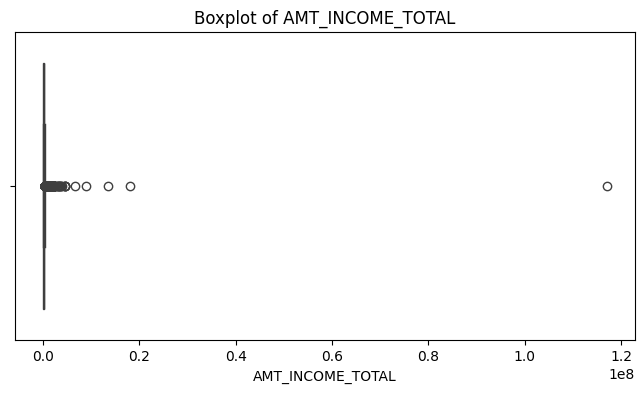

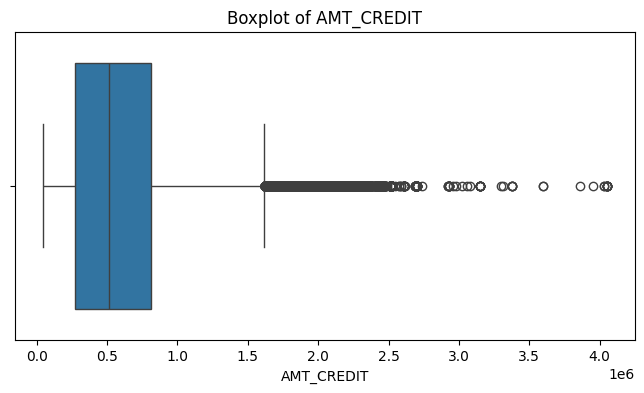

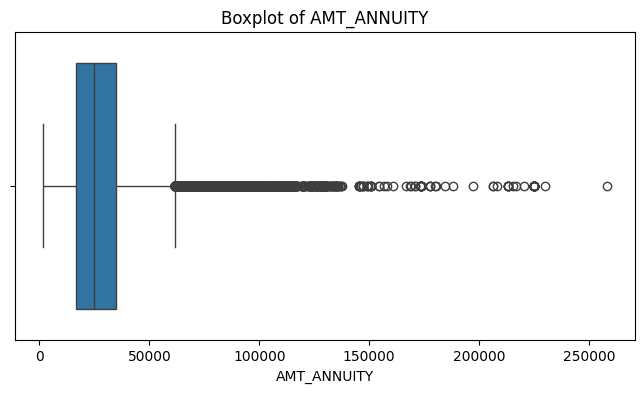

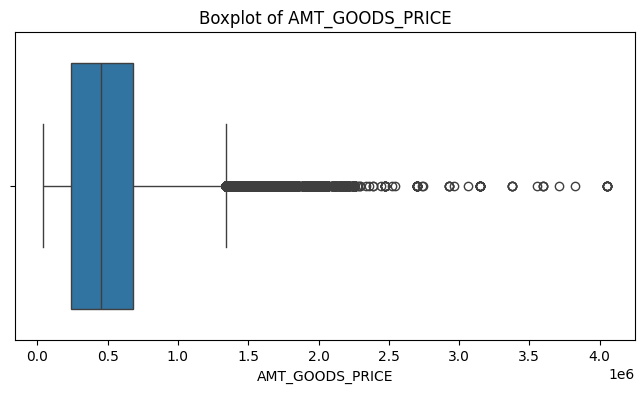

In [78]:
for feature in important_features:

    plt.figure(figsize=(8, 4))

    sns.boxplot(
        data=eda_df,
        x=feature
    )

    plt.title(f"Boxplot of {feature}")

    plt.show()

# Business Insight Table

In [79]:
business_summary = pd.DataFrame({
    "Feature": [
        "Age",
        "Income",
        "Credit Amount",
        "Credit/Income Ratio",
        "EXT_SOURCE_1",
        "EXT_SOURCE_2",
        "EXT_SOURCE_3"
    ],
    
    "Why_it_matters": [
        "Applicant age may be associated with repayment risk",
        "Income indicates repayment capacity",
        "Higher credit obligations may increase financial burden",
        "Measures credit amount relative to income",
        "External creditworthiness information",
        "External creditworthiness information",
        "External creditworthiness information"
    ]
})

business_summary

,Feature,Why_it_matters
0,Age,Applicant age may be associated with repayment...
1,Income,Income indicates repayment capacity
2,Credit Amount,Higher credit obligations may increase financi...
3,Credit/Income Ratio,Measures credit amount relative to income
4,EXT_SOURCE_1,External creditworthiness information
5,EXT_SOURCE_2,External creditworthiness information
6,EXT_SOURCE_3,External creditworthiness information


# EDA Summary

Phase 2 — What you should have learned

By the end of EDA, you should be able to answer:

Dataset

Q: What are we predicting?

Whether an applicant experiences payment difficulties.

Problem type

Q: What type of ML problem is this?

Binary classification.

Major challenge

Q: What's the biggest modeling issue?

Significant class imbalance.

Important features

You should investigate:

EXT_SOURCE_1, EXT_SOURCE_2, EXT_SOURCE_3, age, income, credit amount, and credit-to-income-related features.

Data problems

You have identified:

Missing values, potential outliers, categorical variables, and unusual values such as the DAYS_EMPLOYED anomaly.